Running Perception Stack (Canny & Hough)...
Applying Perspective Transform...
Simulating PID Controller...
 -> Current Cross Track Error (CTE): 2.5
 -> Calculated Steering Angle: -4.128 radians


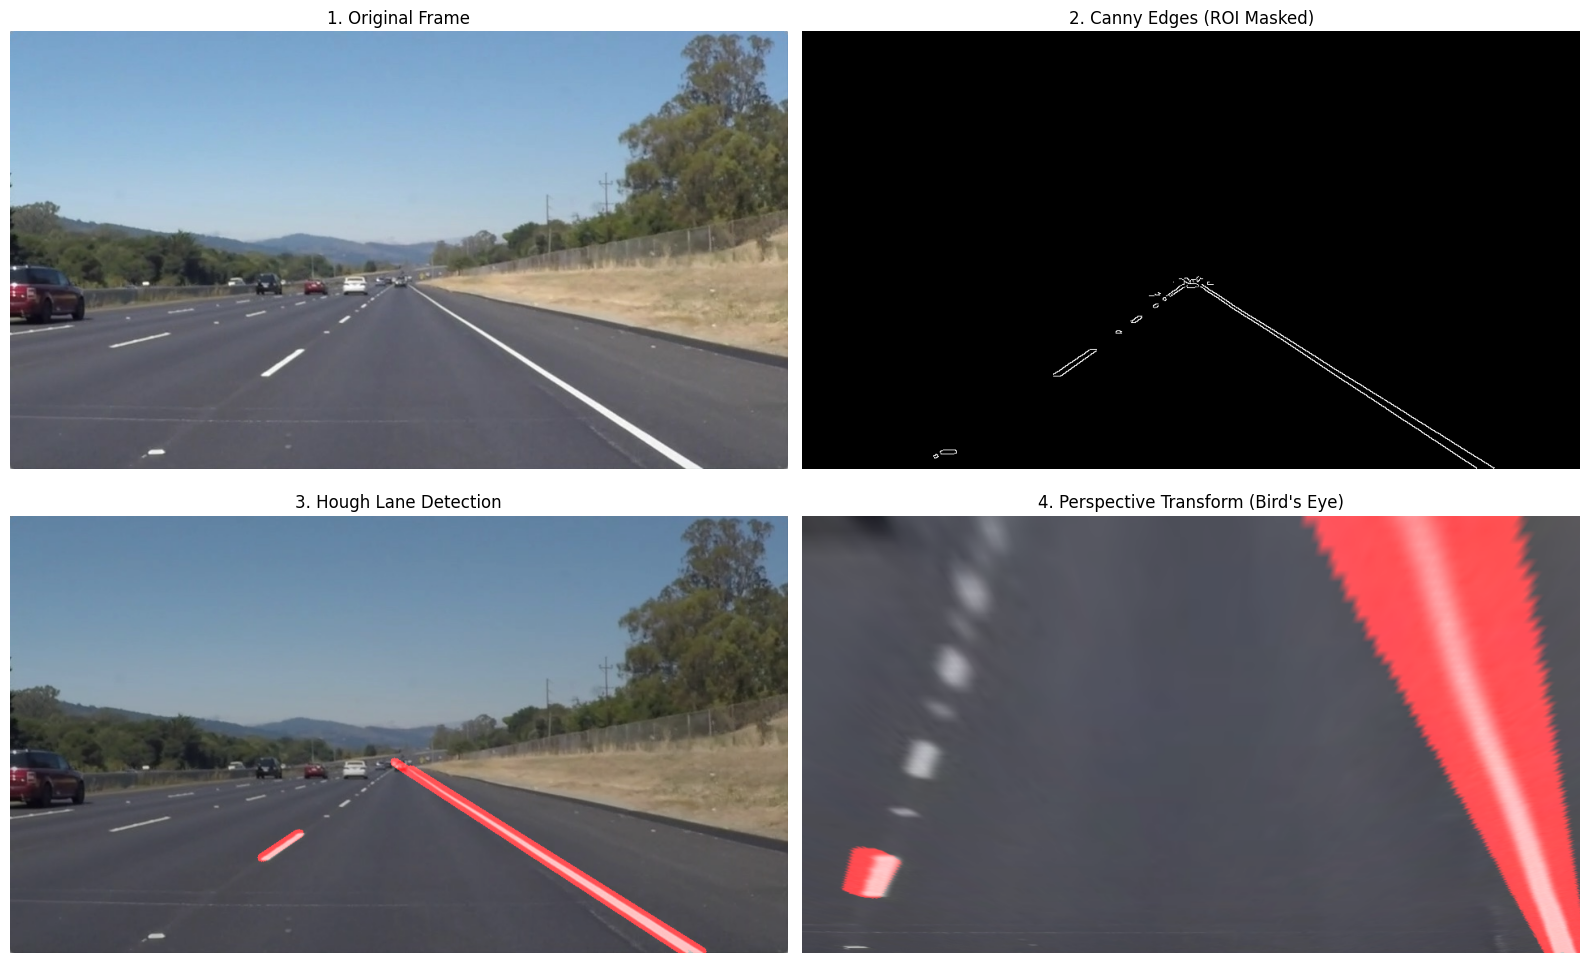

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

# ==========================================
# PART 1: DATA PIPELINE (Auto-Download)
# ==========================================
print("Downloading Udacity test image...")
url = "https://raw.githubusercontent.com/udacity/CarND-LaneLines-P1/master/test_images/solidWhiteRight.jpg"
file_name = "solidWhiteRight.jpg"
urllib.request.urlretrieve(url, file_name)

# Load image and convert to RGB for Matplotlib
image = cv2.imread(file_name)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
height, width = image.shape[:2]

# ==========================================
# PART 2: CANNY EDGE & HOUGH LANE DETECTION
# ==========================================
print("Running Perception Stack (Canny & Hough)...")
# Convert to grayscale and blur
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
blur = cv2.GaussianBlur(gray, (5, 5), 0)

# Canny Edge Detection
edges = cv2.Canny(blur, 50, 150)

# Region of Interest (ROI) Masking
polygons = np.array([
    [(50, height), (width - 50, height), (width // 2, int(height * 0.55))]
])
mask = np.zeros_like(edges)
cv2.fillPoly(mask, polygons, 255)
masked_edges = cv2.bitwise_and(edges, mask)

# Hough Transform for Lane Lines
lines = cv2.HoughLinesP(masked_edges, 2, np.pi/180, 100, np.array([]), minLineLength=40, maxLineGap=5)
line_image = np.zeros_like(image_rgb)

if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line[0]
        cv2.line(line_image, (x1, y1), (x2, y2), (255, 0, 0), 10)

# Overlay lanes on original image
lane_detected_img = cv2.addWeighted(image_rgb, 0.8, line_image, 1, 1)

# ==========================================
# PART 3: PERSPECTIVE TRANSFORM (BIRD'S EYE)
# ==========================================
print("Applying Perspective Transform...")
# Define source points (trapezoid on the lane) and destination points (rectangle)
src_pts = np.float32([[width//2 - 50, height * 0.6], [width//2 + 50, height * 0.6], [100, height], [width - 100, height]])
dst_pts = np.float32([[0, 0], [width, 0], [0, height], [width, height]])

# Calculate Homography Matrix and Warp
matrix = cv2.getPerspectiveTransform(src_pts, dst_pts)
birdseye_view = cv2.warpPerspective(lane_detected_img, matrix, (width, height))

# ==========================================
# PART 4: PID CONTROLLER (CONTROL LOGIC)
# ==========================================
print("Simulating PID Controller...")
class PIDController:
    def __init__(self, kp, ki, kd):
        self.kp = kp
        self.ki = ki
        self.kd = kd
        self.p_error = 0
        self.i_error = 0
        self.d_error = 0

    def update_error(self, cte):
        self.d_error = cte - self.p_error
        self.p_error = cte
        self.i_error += cte

    def total_error(self):
        return -self.kp * self.p_error - self.ki * self.i_error - self.kd * self.d_error

# Initialize PID (Values tuned for typical Udacity simulator)
pid = PIDController(kp=0.15, ki=0.001, kd=1.5)

# Simulate a Cross Track Error (CTE) representing distance from lane center
simulated_cte = 2.5
pid.update_error(simulated_cte)
steering_angle = pid.total_error()

print(f" -> Current Cross Track Error (CTE): {simulated_cte}")
print(f" -> Calculated Steering Angle: {steering_angle:.3f} radians")

# ==========================================
# PART 5: FINAL VISUALIZATION
# ==========================================
fig, axs = plt.subplots(2, 2, figsize=(16, 10))

axs[0, 0].imshow(image_rgb)
axs[0, 0].set_title("1. Original Frame")
axs[0, 0].axis('off')

axs[0, 1].imshow(masked_edges, cmap='gray')
axs[0, 1].set_title("2. Canny Edges (ROI Masked)")
axs[0, 1].axis('off')

axs[1, 0].imshow(lane_detected_img)
axs[1, 0].set_title("3. Hough Lane Detection")
axs[1, 0].axis('off')

axs[1, 1].imshow(birdseye_view)
axs[1, 1].set_title("4. Perspective Transform (Bird's Eye)")
axs[1, 1].axis('off')

plt.tight_layout()
plt.show()